# 09 · Observers and the separation principle

State feedback needs the state, and sensors measure only some of it. A Luenberger observer runs a copy of the
model driven by the same input and corrects it with the measured output: the estimation error obeys
e′ = (A − LC)e, and its poles are placed with the gain L exactly as the controller's are placed with K, by
duality. Combined, the controller and observer give a closed loop whose eigenvalues are simply those of A − BK
and A − LC together - the separation principle. This notebook builds the observer, verifies the principle,
tracks a reference with the right feedforward gain, and shows what an observer costs in robustness.

**What you will learn**
- design a Luenberger observer by duality and interpret its error dynamics
- state and verify the separation principle
- add a reference gain for tracking
- measure the robustness cost of an observer in the loop

**Before you start:** notebook 08  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, statespace as sp, response as rs, frequency as fr, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## An observer for the pendulum, from the angle and the position

observer gain L (4 x 2) =
 [[ 22.97   0.59]
 [127.33   4.37]
 [ -0.23  22.84]
 [  3.52 161.59]]
eig(A - L C) = [-13. -12. -11. -10.]


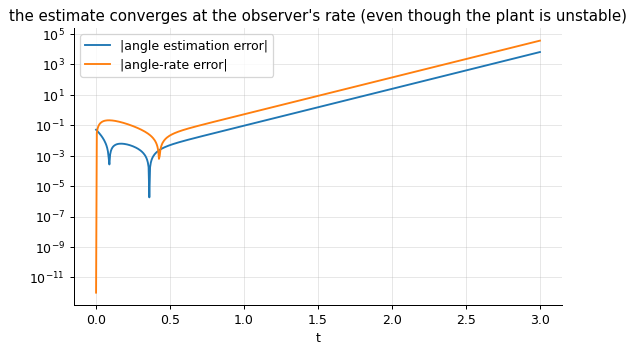

In [2]:
cp = models.cart_pendulum()["system"]
A, B, C = cp.A, cp.B, cp.C
K = sp.place(A, B, [-2 + 2j, -2 - 2j, -5.0, -6.0])
L = sp.observer_gain(A, C, [-10.0, -11.0, -12.0, -13.0])              # observer poles 2-5 times faster than the controller's
print("observer gain L (4 x 2) =\n", np.round(L, 2))
print("eig(A - L C) =", np.round(np.sort(np.linalg.eigvals(A - L @ C).real), 6))
obs = sp.observer(cp, L)
# simulate plant + observer from different initial states, open loop (u = 0 small perturbation)
t = np.linspace(0, 3, 601)
x0 = np.array([0.0, 0.0, 0.05, 0.0]); xh0 = np.zeros(4)
_, y_plant, x_plant = rs.initial(cp, x0, 3.0, 601)
uy = np.column_stack([np.zeros(601), y_plant])                     # observer inputs: [u, y1, y2]
_, xh, _ = rs.lsim(obs, uy, t, x0=xh0)
err = x_plant - xh
plt.semilogy(t, np.abs(err[:, 2]) + 1e-12, label="|angle estimation error|"); plt.semilogy(t, np.abs(err[:, 3]) + 1e-12, label="|angle-rate error|"); plt.legend(); plt.xlabel("t"); plt.title("the estimate converges at the observer's rate (even though the plant is unstable)"); plt.show()

The observer starts from a wrong state (zero, while the pendulum is at 3°) and its error decays like e^{−10t},
the slowest observer pole - while the plant itself is running away. Nothing about the plant's stability enters
the observer's convergence: the error dynamics are A − LC, chosen freely because (A, C) is observable. The
observer gain is placed on the dual system (Aᵀ, Cᵀ), the same computation as pole placement.

## The separation principle

In [3]:
cl = sp.closed_loop_with_observer(cp, K, L)
print("closed-loop eigenvalues (state and estimation error):", np.round(np.sort_complex(cl.poles()), 4))
print("= controller poles", np.round(np.sort_complex(np.linalg.eigvals(A - B @ K)), 4), "+ observer poles", np.round(np.sort(np.linalg.eigvals(A - L @ C).real), 4))
reg = sp.regulator(cp, K, L)
print("\nthe compensator (from [r, y1, y2] to u) has order", reg.n, "- the observer's state; its own poles", np.round(np.sort_complex(reg.poles()), 3), "need not be stable (here they are)")

closed-loop eigenvalues (state and estimation error): [-13.+0.j -12.+0.j -11.+0.j -10.+0.j  -6.+0.j  -5.+0.j  -2.-2.j  -2.+2.j]
= controller poles [-6.+0.j -5.+0.j -2.-2.j -2.+2.j] + observer poles [-13. -12. -11. -10.]

the compensator (from [r, y1, y2] to u) has order 4 - the observer's state; its own poles [-19.244-15.23j -19.244+15.23j -12.967 +0.j    -9.364 +0.j  ] need not be stable (here they are)


The closed loop in the coordinates (x, e = x − x̂) has a block-triangular matrix: the estimation error does not
depend on the control, and the control drives x with x̂ = x − e. Its eigenvalues are exactly the union of the
two designed sets - design the controller as if the state were known, design the observer as if there were no
controller, and the pair works. The compensator that results is a dynamic system of the observer's order, an
output-feedback controller like any classical one, and its own poles are not the closed-loop poles.

## Tracking a reference

reference gain Nbar = 1000.000: the step response settles at 1.0000 (not 1 without it: 0.0010)


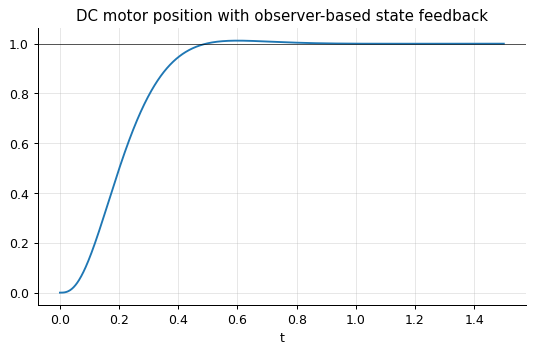

In [4]:
mot = models.dc_motor(position=True)["system"]
Km = sp.place(mot.A, mot.B, [-8 + 6j, -8 - 6j, -20.0])
Lm = sp.observer_gain(mot.A, mot.C, [-40.0, -45.0, -50.0])
Nbar = sp.reference_gain(mot.A, mot.B, mot.C, Km)
cl_m = sp.closed_loop_with_observer(mot, Km, Lm, Nbar)
t, y = rs.step(cl_m, 1.5)
print(f"reference gain Nbar = {Nbar:.3f}: the step response settles at {y[-1]:.4f} (not 1 without it: {rs.step(sp.closed_loop_with_observer(mot, Km, Lm, 1.0), 1.5)[1][-1]:.4f})")
plt.plot(t, y); plt.axhline(1, color="k", lw=0.5); plt.xlabel("t"); plt.title("DC motor position with observer-based state feedback"); plt.show()

State feedback regulates to zero; to follow a reference the input must be scaled by N̄ = 1/(C(−A + BK)⁻¹B) so
that the closed loop's dc gain is one. This is an open-loop correction - exact for the model, off for the real
plant - which is why integral action (notebook 10's LQR with an integrator) is preferred when the gain is
uncertain.

## What an observer costs: the LQG robustness problem in miniature

In [5]:
Pm = mot.to_tf()
# loop transfer at the plant input with full state feedback vs with the observer in the loop
L_state = sy.ss(mot.A, mot.B, Km, np.zeros((1, 1))).to_tf()
comp = sy.ss(mot.A - mot.B @ Km - Lm @ mot.C, Lm, Km, np.zeros((1, 1)))     # the compensator from y to -u
L_obs = sy.series(Pm, comp.to_tf())
for name, L_ in (("full state feedback", L_state), ("with the observer in the loop", L_obs)):
    m = fr.margins(L_)
    print(f"{name:<32}: gain margin {m['gain_margin']:.2f}, phase margin {m['phase_margin']:.1f} deg")

full state feedback             : gain margin inf, phase margin 78.5 deg
with the observer in the loop   : gain margin 3.89, phase margin 46.4 deg


With the true state fed back the loop has an infinite gain margin and a comfortable phase margin; once the
observer supplies the state the margins shrink, because the compensator's dynamics add phase in the loop.
Doyle's 1978 observation that LQG has *no* guaranteed margins is this effect in general: the separation
principle guarantees nominal stability, not robustness, and the observer's speed and noise properties must be
chosen with the loop's margins in view (loop transfer recovery, in notebook 11's exercises).

## Inside the algorithm: the error dynamics

In [6]:
E = A - L @ C
print("the estimation error obeys e' = (A - L C) e, independent of u and of x; its eigenvalues", np.round(np.sort(np.linalg.eigvals(E).real), 3))
print("block-triangular closed loop: the lower-left block is zero ->", np.max(np.abs(cl.A[4:, :4])))

the estimation error obeys e' = (A - L C) e, independent of u and of x; its eigenvalues [-13. -12. -11. -10.]
block-triangular closed loop: the lower-left block is zero -> 0.0


## Exercises
1. Place the observer poles at 2, 5 and 20 times the controller's slowest pole and compare the step responses, the sensitivity to measurement noise (simulate with noise added to y) and the loop margins. Where is the sweet spot?
2. Design a reduced-order observer for the DC motor that estimates only the current from the measured speed (the speed is measured, so only one state needs estimating). Compare its order and convergence with the full-order observer.
3. **Implement it yourself:** build the observer-based compensator from (A, B, C, K, L) as a transfer function from y to u and close the loop with the plant in the transfer-function domain; confirm that the closed-loop poles are the union of the two designed sets.